# MODELIZACIÓN REGRESIÓN EXPOSURE AT DEFAULT

## IMPORTAR PAQUETES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
import os
from pathlib import Path
import openpyxl
import sqlalchemy as sa

# Desactivar notación científica
pd.set_option('display.float_format', lambda x: '%.3f' % x)
np.set_printoptions(suppress=True)

#RUTAS
# ── Rutas del proyecto ────────────────────────────────────────────────
# Se resuelven desde la ubicación del notebook, así funcionan
# igual en cualquier máquina
RAIZ = Path.cwd().parent

ORIGINALES   = RAIZ / '02_datos' / '01_Originales'
VALIDACION   = RAIZ / '02_datos' / '02_Validacion'
ENTRENAMIENTO = RAIZ / '02_datos' / '03_Entrenamiento'
CACHES       = RAIZ / '02_datos' / '04_Caches'
MODELOS      = RAIZ / '05_modelos'
RESULTADOS   = RAIZ / '06_resultados'

# ----------USO DE UTILS.PY------------
import sys
from pathlib import Path
# Subir de 03_notebooks a 03_RIESGOS
ROOT = Path.cwd().parent
# Añadir 04_scripts a las rutas de búsqueda
sys.path.insert(0, str(ROOT / "04_scripts"))
#---------------------------------------

# Cargar variables de entorno
load_dotenv()

print("✅ Librerías importadas correctamente")

✅ Librerías importadas correctamente


## MODELIZACIÓN REGRESION EXPOSURE AT DEFAULT

### IMPORTAR LOS DATOS

In [2]:
df = pd.read_pickle(ENTRENAMIENTO / "df_tablon_ead.pkl")

### CREAR X e Y

In [3]:
from sklearn.model_selection import train_test_split

x = df.drop(columns=["target_ead","target_pd"])
y = df["target_ead"]
x_train,x_test,y_train,y_val = train_test_split(x, y, test_size=0.3, random_state=42)

### MODELIZAR

#### Crear el pipe y el diccionario de algorimos, parámetros y valores a testar

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import HistGradientBoostingRegressor

pipe = Pipeline([('algoritmo', Ridge())])   # el nombre del paso es solo una etiqueta fija

grid = [
    {'algoritmo': [Ridge()],
     'algoritmo__alpha': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]},

    {'algoritmo': [Lasso()],
     'algoritmo__alpha': [0.0001, 0.001, 0.01, 0.05, 0.1]},

    # min_samples_leaf=100: hojas con al menos 100 casos, evita sobreajuste
    # scoring: métrica de la parada temprana, no la del grid
    {'algoritmo': [HistGradientBoostingRegressor(min_samples_leaf=60,
                                                 scoring='neg_mean_absolute_error')],
     'algoritmo__learning_rate': [0.01, 0.025, 0.05, 0.1],
     'algoritmo__max_iter': [50, 100, 200],
     'algoritmo__max_depth': [5, 10, 20],
     'algoritmo__l2_regularization': [0, 0.25, 0.5, 0.75, 1]}
]

#### Optimizar los hiper parámetros

#####  Con grid search

In [5]:
from sklearn.model_selection import GridSearchCV
grid_search = GridSearchCV(pipe, grid, cv=4, scoring='neg_mean_absolute_error', n_jobs=-1)
modelo = grid_search.fit(x_train, y_train)

In [6]:
#quiero tomar los parametros del mejor modelo para usarlo en un nuevo modelo
grid_search.best_params_

{'algoritmo': Ridge(), 'algoritmo__alpha': 0.1}

In [7]:
# Sin la tasa ni la cuota el grid prefiere un modelo lineal (Ridge); con HistGradientBoosting el error es el mismo
modelo_ead = Ridge(alpha=0.1)
modelo_ead.fit(x_train, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

### EVALUAR

#### Predecir sobre validación

In [8]:
pred = modelo_ead.predict(x_test)

Al ser un modelo de regresion y estar en porcentaje la variable objetivo no tendria sentido que
tuviera valores por encima de los limites, pero, de todas formas se eliminan los maximos y minimos por si acaso

In [9]:
pred = np.where(pred < 0, 0, pred)  # reemplazar predicciones negativas por 0
pred = np.where(pred > 1, 1, pred)  # reemplazar predicciones mayores a 1 por 1

#### Evaluar sobre validación

In [10]:
from sklearn.metrics import mean_absolute_error
mean_absolute_error(y_val, pred)

0.16223742802371596

### REPORTING DEL MODELO

In [11]:
check_validation = pd.DataFrame({"y_val": y_val, "pred": pred})
check_validation

,y_val,pred
id_cliente,,
56051627,0.487,0.640
109923302,0.759,0.693
1486619,0.751,0.781
7367379,0.865,0.692
86031234,0.882,0.785
...,...,...
6726625,0.656,0.734
130533642,0.888,0.632
1247820,0.769,0.613


Podemos analizarlo gráficamente con gráficos de residuos.

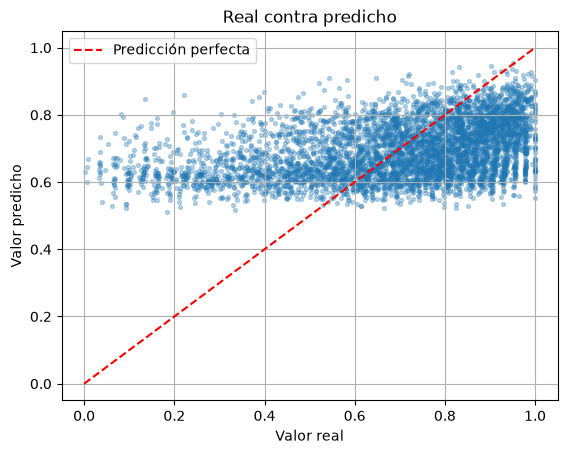

,casos,real_medio,pred_medio,error_medio
target_ead,,,,
"(-0.001, 0.2]",188,0.125,0.637,0.511
"(0.2, 0.4]",391,0.312,0.642,0.331
"(0.4, 0.6]",813,0.512,0.666,0.155
"(0.6, 0.8]",1582,0.709,0.688,0.075
"(0.8, 1.0]",1991,0.894,0.728,0.168


In [12]:
plt.scatter(y_val, pred, alpha=0.3, s=8)
plt.plot([0, 1], [0, 1], 'r--', label='Predicción perfecta')
plt.xlabel('Valor real'); plt.ylabel('Valor predicho')
plt.title('Real contra predicho'); plt.legend(); plt.grid(True)
plt.show()

tramos = pd.cut(y_val, [0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True)
(pd.DataFrame({'real': y_val, 'pred': pred, 'error_abs': (y_val - pred).abs()})
   .groupby(tramos, observed=True)
   .agg(casos=('real', 'size'), real_medio=('real', 'mean'),
        pred_medio=('pred', 'mean'), error_medio=('error_abs', 'mean'))
   .round(3))

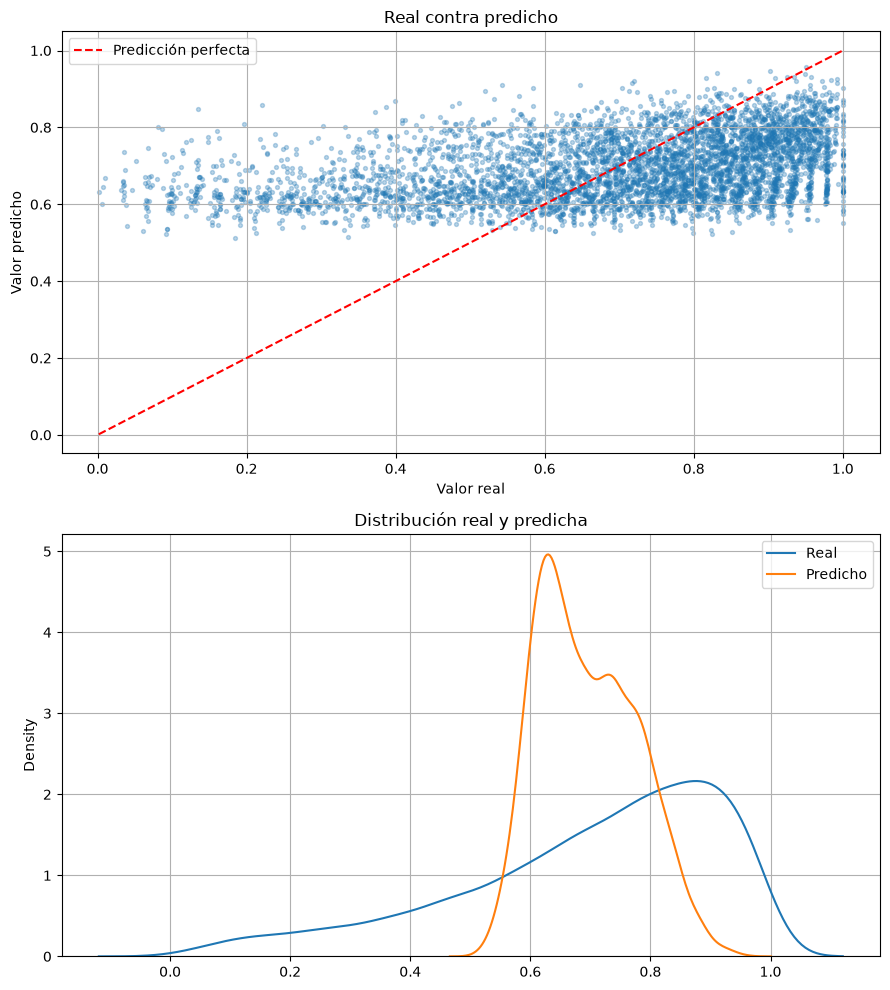

MAE: 0.162  |  error medio sobre el real medio: 23.3%


,casos,real_medio,pred_medio,error_medio
"(0.00068, 0.519]",993,0.340,0.649,0.309
"(0.519, 0.689]",993,0.613,0.675,0.083
"(0.689, 0.8]",993,0.747,0.694,0.082
"(0.8, 0.893]",993,0.848,0.715,0.136
"(0.893, 1.0]",993,0.941,0.741,0.200


In [13]:
import importlib, utils
importlib.reload(utils)
from utils import reporting_regresion
reporting_regresion(y_val, pred)

### Cómo leer estos gráficos

**Real contra predicho.** Cada punto es un préstamo. Abajo está lo que el cliente debía de verdad cuando falló, y a la izquierda lo que el modelo predijo. Si el modelo acertara, los puntos caerían sobre la diagonal roja. Aquí forman una franja casi horizontal entre el 60 % y el 80 %: el modelo predice casi lo mismo para todos.

**Densidad real y predicha.** La curva real es ancha porque hay préstamos que se debían casi por completo y otros casi nada. La curva predicha es estrecha y está en el centro, cerca del 70 %. Esa diferencia de anchura muestra que el modelo se concentra en un valor típico y no llega a los extremos.

**Tabla por tramos.** Un cliente que debía muy poco (13 % en promedio) aparece con una predicción cercana al 64 %. Uno que debía casi todo (89 %) aparece con cerca de 73 %. Donde más se equivoca es en los que debían poco, y ahí el modelo se pasa (lado prudente). En los que debían casi todo se queda corto, que es el lado que más pérdida puede traer.

**Por qué pasa.** Con las variables que se conocen al conceder el préstamo, el modelo no puede saber cuánto habrá pagado el cliente antes de fallar. Cuando no hay información suficiente, predice un valor típico.

**Cómo usarlo.** Sirve para ordenar el riesgo de forma aproximada y es fiable en los casos típicos, pero no para fijar el monto exacto de un cliente en los extremos.

In [14]:
df['target_ead'].describe().T

count   16549.000
mean        0.695
std         0.219
min         0.000
25%         0.566
50%         0.745
75%         0.869
max         1.000
Name: target_ead, dtype: float64